# Fase II. Clasificación de variedad de arroz con CNN

**Objetivo:** Clasificar una imagen de un grano de arroz en una de sus 5 variedades (Arborio, Basmati, Ipsala, Jasmine, Karacadag).

## 1. Obtención de datos y configuración

In [ ]:
import os, random
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__, "| GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
#descargar el dataset de arroz desde Kaggle y localizar sus carpetas
!pip -q install kagglehub
import kagglehub

ruta_descarga = kagglehub.dataset_download("muratkokludataset/rice-image-dataset")

"""Busca dentro de la descarga la carpeta que contiene las carpetas de cada variedad."""
def encontrar_carpeta_con_clases(ruta_inicial):
    for carpeta_actual, subcarpetas, _ in os.walk(ruta_inicial):
        #si aquí están las carpetas de Basmati y Jasmine, esta es la carpeta correcta
        if 'Basmati' in subcarpetas and 'Jasmine' in subcarpetas:
            return carpeta_actual


DATA_DIR = encontrar_carpeta_con_clases(ruta_descarga)

#cada subcarpeta de DATA_DIR es una clase (variedad de arroz)
nombres_en_carpeta = os.listdir(DATA_DIR)
CLASSES = []
for nombre in nombres_en_carpeta:
    ruta_completa = os.path.join(DATA_DIR, nombre)
    if os.path.isdir(ruta_completa):
        CLASSES.append(nombre)
CLASSES = sorted(CLASSES)

print("Ruta:", DATA_DIR)
print("Clases:", CLASSES)

#contar cuántas imágenes tiene cada variedad
for nombre_clase in CLASSES:
    carpeta_clase = os.path.join(DATA_DIR, nombre_clase)
    cantidad_de_imagenes = len(os.listdir(carpeta_clase))
    print("\n" + carpeta_clase)
    print(nombre_clase, cantidad_de_imagenes, "imágenes")

Using Colab cache for faster access to the 'rice-image-dataset' dataset.
Ruta: /kaggle/input/rice-image-dataset/Rice_Image_Dataset
Clases: ['Arborio', 'Basmati', 'Ipsala', 'Jasmine', 'Karacadag']

/kaggle/input/rice-image-dataset/Rice_Image_Dataset/Arborio
Arborio 15000 imágenes

/kaggle/input/rice-image-dataset/Rice_Image_Dataset/Basmati
Basmati 15000 imágenes

/kaggle/input/rice-image-dataset/Rice_Image_Dataset/Ipsala
Ipsala 15000 imágenes

/kaggle/input/rice-image-dataset/Rice_Image_Dataset/Jasmine
Jasmine 15000 imágenes

/kaggle/input/rice-image-dataset/Rice_Image_Dataset/Karacadag
Karacadag 15000 imágenes


Tamaño original de una imagen: (250, 250, 3)


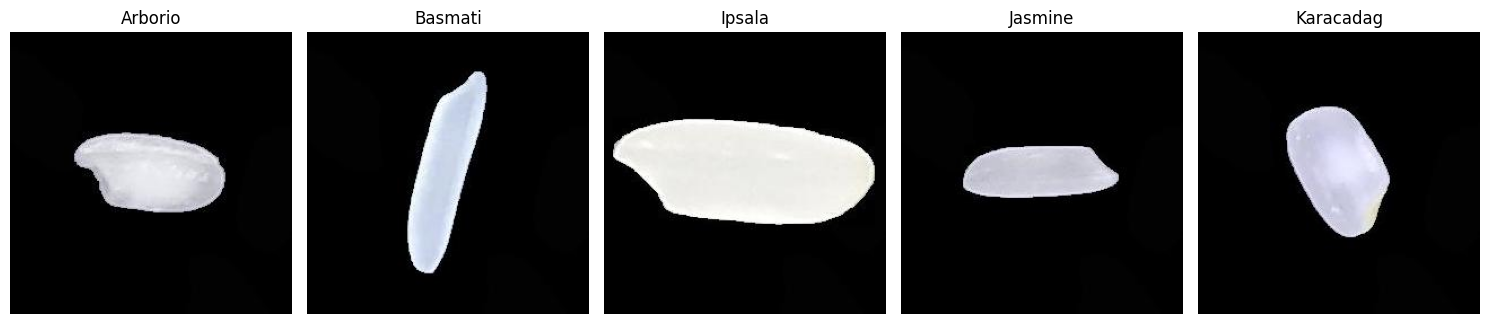

In [ ]:
#mostrar una imagen de ejemplo de cada variedad de arroz
numero_de_clases = len(CLASSES)
figura, ejes = plt.subplots(1, numero_de_clases, figsize=(15, 3.5))

for eje, nombre_clase in zip(ejes, CLASSES):
    #carpeta que contiene las imágenes de esta variedad
    carpeta_clase = os.path.join(DATA_DIR, nombre_clase)

    #tomar el primer archivo (en orden alfabético) como ejemplo
    archivos = sorted(os.listdir(carpeta_clase))
    primer_archivo = archivos[0]

    #cargar la imagen desde el disco
    ruta_imagen = os.path.join(carpeta_clase, primer_archivo)
    imagen = plt.imread(ruta_imagen)

    #dibujarla en su recuadro, con el nombre de la variedad y sin ejes
    eje.imshow(imagen)
    eje.set_title(nombre_clase)
    eje.axis('off')

#mostrar la forma (alto, ancho, canales) de la última imagen cargada
print("Tamaño original de una imagen:", imagen.shape)

plt.tight_layout()
plt.show()

## 2. División en entrenamiento, validación y prueba

Se utiliza un subconjunto balanceado (N_PER_CLASS por variedad) con división estratificada 70 / 15 / 15.

In [ ]:
#elegir 3,000 imágenes por variedad y dividirlas
#en entrenamiento, validación y prueba
IMAGENES_POR_CLASE = 3000

rutas_imagenes = []   #aquí se guardará la ruta de cada imagen elegida
etiquetas = []        #aquí se guardará el número de clase de cada imagen

for numero_de_clase, nombre_clase in enumerate(CLASSES):
    #carpeta con todas las imágenes de esta variedad
    carpeta_clase = os.path.join(DATA_DIR, nombre_clase)

    #lista de nombres de archivo, en orden alfabético
    nombres_archivos = sorted(os.listdir(carpeta_clase))

    #elegir al azar 3,000 archivos (siempre los mismos, gracias a la semilla)
    generador_aleatorio = random.Random(SEED)
    archivos_elegidos = generador_aleatorio.sample(nombres_archivos, IMAGENES_POR_CLASE)

    #guardar la ruta completa de cada imagen elegida
    for nombre_archivo in archivos_elegidos:
        ruta = os.path.join(carpeta_clase, nombre_archivo)
        rutas_imagenes.append(ruta)

    #guardar el número de clase, repetido una vez por imagen
    etiquetas.extend([numero_de_clase] * IMAGENES_POR_CLASE)


#paso 1: separar 70 % para entrenamiento y 30 % temporal
p_train, rutas_temporales, y_train, etiquetas_temporales = train_test_split(
    rutas_imagenes,
    etiquetas,
    test_size=0.30,
    stratify=etiquetas,
    random_state=SEED,
)

#paso 2: dividir ese 30 % por la mitad: 15 % validación y 15 % prueba
p_val, p_test, y_val, y_test = train_test_split(
    rutas_temporales,
    etiquetas_temporales,
    test_size=0.50,
    stratify=etiquetas_temporales,
    random_state=SEED,
)

print("Entrenamiento:", len(p_train), "| Validación:", len(p_val), "| Prueba:", len(p_test))

Entrenamiento: 10500 | Validación: 2250 | Prueba: 2250


## 3. Preprocesamiento: Preprocesar las imágenes y construir los conjuntos de datos para entrenar la CNN



*   Estandarizar el tamaño de las imagenes a 128 x 128 píxeles (redimensionar).
*   Normalizar (escalar) los píxeles a [0, 1] diviendo entre 255.
*   Opción de escala de grises.
*   Codificación de etiquetas en one-hot (5 clases).



In [ ]:
#configuracion

#tamaño al que se redimensionan las imágenes (alto, ancho)
IMG_SIZE = (128, 128)

#cuántas imágenes se procesan juntas en cada paso
BATCH = 32

#True = convertir a escala de grises, False = conservar el color
GRAYSCALE = False


if GRAYSCALE:
    #un canal (gris)
    CH = 1
else:
    #tres canales (rojo, verde, azul)
    CH = 3

#número de variedades (5)
N_CLASSES = len(CLASSES)

Recibe la ruta de una imagen y su número de clase. Devuelve la imagen lista para la red y la etiqueta en formato one-hot.

In [ ]:
def cargar_y_preprocesar_imagen(ruta, etiqueta):
    #leer el archivo del disco (todavía son bytes, no una imagen)
    contenido_archivo = tf.io.read_file(ruta)

    #convertir los bytes del JPG en una imagen de 3 canales (color)
    imagen = tf.image.decode_jpeg(contenido_archivo, channels=3)

    #cambiar el tamaño a 128 x 128 píxeles
    imagen = tf.image.resize(imagen, IMG_SIZE)

    #si se pidió, pasar a escala de grises (de 3 canales a 1)
    if GRAYSCALE:
        imagen = tf.image.rgb_to_grayscale(imagen)

    #convertir a decimales y escalar los píxeles de 0-255 a 0-1
    imagen = tf.cast(imagen, tf.float32)
    imagen = imagen / 255.0

    #convertir el número de clase en un vector one-hot (ej. 2 -> [0, 0, 1, 0, 0])
    etiqueta_one_hot = tf.one_hot(etiqueta, N_CLASSES)

    return imagen, etiqueta_one_hot

Convierte listas de rutas y etiquetas en un dataset listo para el modelo.

In [ ]:
def crear_dataset(rutas, etiquetas, mezclar=False):
    #cada elemento del dataset es un par (ruta, etiqueta)
    dataset = tf.data.Dataset.from_tensor_slices((rutas, etiquetas))

    #si se pidió, mezclar el orden de todos los elementos
    if mezclar:
        dataset = dataset.shuffle(len(rutas), seed=SEED)

    #aplicar la función de preprocesamiento a cada elemento
    dataset = dataset.map(cargar_y_preprocesar_imagen, num_parallel_calls=tf.data.AUTOTUNE)

    #agrupar en lotes de 32
    dataset = dataset.batch(BATCH)

    #ir preparando el siguiente lote mientras el modelo trabaja con el actual
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

In [ ]:
#crear los tres conjuntos (solo el de entrenamiento se mezcla)
train_ds = crear_dataset(p_train, y_train, mezclar=True)
val_ds   = crear_dataset(p_val, y_val)
test_ds  = crear_dataset(p_test, y_test)

#comprobación: revisar un lote de ejemplo
imagenes_lote, etiquetas_lote = next(iter(train_ds))

valor_minimo = float(tf.reduce_min(imagenes_lote))
valor_maximo = float(tf.reduce_max(imagenes_lote))

print("Lote de imágenes:", imagenes_lote.shape, "| rango:", valor_minimo, "a", valor_maximo)
print("Lote de etiquetas (one-hot):", etiquetas_lote.shape)

Lote de imágenes: (32, 128, 128, 3) | rango: 0.0 a 1.0
Lote de etiquetas (one-hot): (32, 5)


## 4. Construcción y entrenamiento de la CNN



Arquitectura: aumento de datos, 3 bloques Conv2D + MaxPooling (32, 64, 128 filtros), Flatten, capa densa de 128 con Dropout y salida softmax de 5 clases.

Construir y compilar la red neuronal convolucional (CNN)

In [ ]:
#forma de cada imagen de entrada: (alto, ancho, canales) = (128, 128, 3)
forma_de_entrada = (*IMG_SIZE, CH)

model = keras.Sequential([

    #entrada y aumento de datos (solo actúa durante el entrenamiento)
    layers.Input(shape=forma_de_entrada),
    #voltea la imagen al azar
    layers.RandomFlip(mode="horizontal_and_vertical"),
    #gira la imagen al azar
    layers.RandomRotation(factor=0.1),

    #bloque convolucional 1: detecta rasgos simples (bordes, contornos)
    layers.Conv2D(filters=32, kernel_size=3, activation='relu', padding='same'),
    layers.MaxPooling2D(),

    #bloque convolucional 2: combina rasgos simples en formas
    layers.Conv2D(filters=64, kernel_size=3, activation='relu', padding='same'),
    layers.MaxPooling2D(),

    #bloque convolucional 3: rasgos más complejos del grano
    layers.Conv2D(filters=128, kernel_size=3, activation='relu', padding='same'),
    layers.MaxPooling2D(),

    #clasificador

    #aplana el mapa de rasgos a un vector
    layers.Flatten(),

    #capa densa que combina los rasgos
    layers.Dense(units=128, activation='relu'),

    #apaga neuronas al azar para evitar sobreajuste
    layers.Dropout(rate=0.5),

    #salida: probabilidad de cada variedad
    layers.Dense(units=N_CLASSES, activation='softmax'),

], name="cnn_arroz")


#configurar cómo aprende el modelo
optimizador = keras.optimizers.Adam(learning_rate=0.001)

model.compile(
    optimizer=optimizador,
    loss='categorical_crossentropy',
    metrics=['accuracy'],
)

#mostrar un resumen de capas, formas de salida y parámetros
model.summary()

Model: "cnn_arroz"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,325 (16.36 MB)

 Trainable params: 4,288,325 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

Entrenar la CNN con vigilancia automática del sobreajuste

In [ ]:
#número máximo de épocas (vueltas completas sobre los datos de entrenamiento)
EPOCHS = 15

#callbacks: acciones automáticas que se ejecutan al final de cada época
detener_si_no_mejora = keras.callbacks.EarlyStopping(

    #qué vigilar: la pérdida en validación
    monitor='val_loss',

    #cuántas épocas seguidas sin mejorar se toleran
    patience=4,

    #al terminar, regresar a los mejores pesos
    restore_best_weights=True,
)

guardar_mejor_modelo = keras.callbacks.ModelCheckpoint(
    #archivo donde se guarda el modelo
    filepath='mejor_modelo_arroz.keras',

    #qué vigilar para decidir cuál es el mejor
    monitor='val_loss',

    #guardar solo cuando mejora
    save_best_only=True,
)

lista_de_callbacks = [detener_si_no_mejora, guardar_mejor_modelo]

#entrenar el modelo
#el resultado guarda el historial de cada época
history = model.fit(
    #datos de entrenamiento (imágenes + etiquetas)
    train_ds,
    #datos para medir el progreso en cada época
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=lista_de_callbacks,
)

Epoch 1/15
329/329 ━━━━━━━━━━━━━━━━━━━━ 24s 66ms/step - accuracy: 0.8912 - loss: 0.3076 - val_accuracy: 0.9551 - val_loss: 0.1137
Epoch 2/15
329/329 ━━━━━━━━━━━━━━━━━━━━ 29s 32ms/step - accuracy: 0.9447 - loss: 0.1607 - val_accuracy: 0.9653 - val_loss: 0.1041
Epoch 3/15
329/329 ━━━━━━━━━━━━━━━━━━━━ 12s 36ms/step - accuracy: 0.9515 - loss: 0.1408 - val_accuracy: 0.9684 - val_loss: 0.0936
Epoch 4/15
329/329 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.9595 - loss: 0.1206 - val_accuracy: 0.9813 - val_loss: 0.0578
Epoch 5/15
329/329 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.9720 - loss: 0.0878 - val_accuracy: 0.9902 - val_loss: 0.0277
Epoch 6/15
329/329 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.9782 - loss: 0.0701 - val_accuracy: 0.9818 - val_loss: 0.0554
Epoch 7/15
329/329 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.9806 - loss: 0.0574 - val_accuracy: 0.9916 - val_loss: 0.0269
Epoch 8/15
329/329 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.9848 - loss: 0.0461 - 

## 5. Evaluación de resultados

Graficar las curvas de entrenamiento: precisión y pérdida por época

In [ ]:
mejor_epoca = int(np.argmin(history.history['val_loss'])) + 1
mejor_perdida_val = min(history.history['val_loss'])
mejor_precision_val = history.history['val_accuracy'][mejor_epoca - 1]

print("Mejor época:", mejor_epoca)
print("val_loss:", round(mejor_perdida_val, 4), "| val_accuracy:", round(mejor_precision_val, 4))

Mejor época: 8
val_loss: 0.0109 | val_accuracy: 0.996


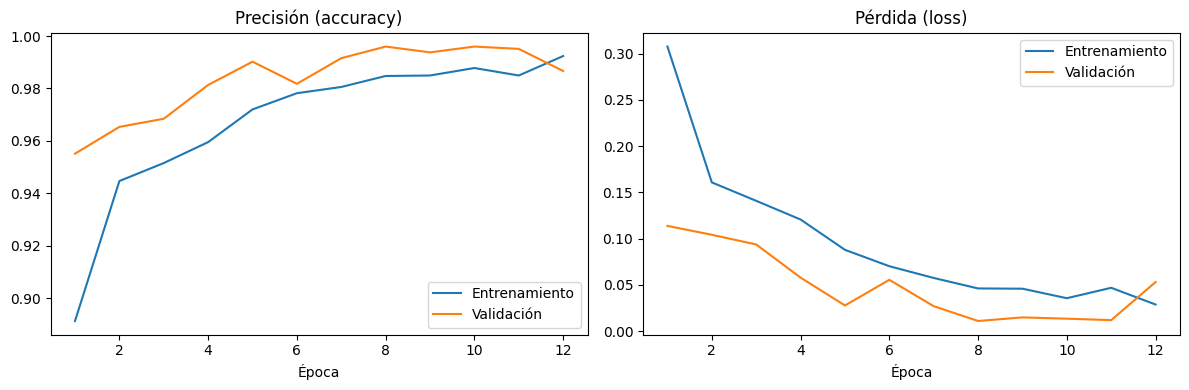

In [ ]:
#diccionario con las métricas de cada época
historial = history.history

#números de época para el eje horizontal: 1, 2, 3, ..., hasta las que se corrieron
numero_de_epocas = len(historial['loss'])
epocas = range(1, numero_de_epocas + 1)

#una figura con dos gráficas lado a lado
figura, ejes = plt.subplots(1, 2, figsize=(12, 4))
grafica_precision = ejes[0]
grafica_perdida = ejes[1]

#gráfica izquierda: precisión (accuracy)
grafica_precision.plot(epocas, historial['accuracy'], label='Entrenamiento')
grafica_precision.plot(epocas, historial['val_accuracy'], label='Validación')
grafica_precision.set_title('Precisión (accuracy)')
grafica_precision.set_xlabel('Época')
grafica_precision.legend()

#gráfica derecha: pérdida (loss)
grafica_perdida.plot(epocas, historial['loss'], label='Entrenamiento')
grafica_perdida.plot(epocas, historial['val_loss'], label='Validación')
grafica_perdida.set_title('Pérdida (loss)')
grafica_perdida.set_xlabel('Época')
grafica_perdida.legend()

#acomodar los elementos para que no se encimen, guardar la imagen y mostrarla
plt.tight_layout()
plt.savefig('curvas_entrenamiento.png', dpi=150)
plt.show()

Evaluar el modelo con el conjunto de prueba (imágenes que nunca vio al entrenar)

71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.9951 - loss: 0.0165
Prueba -> pérdida: 0.0165 | precisión: 0.9951
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step
              precision    recall  f1-score   support

     Arborio     0.9955    0.9911    0.9933       450
     Basmati     0.9978    0.9911    0.9944       450
      Ipsala     1.0000    0.9978    0.9989       450
     Jasmine     0.9890    0.9956    0.9922       450
   Karacadag     0.9934    1.0000    0.9967       450

    accuracy                         0.9951      2250
   macro avg     0.9951    0.9951    0.9951      2250
weighted avg     0.9951    0.9951    0.9951      2250



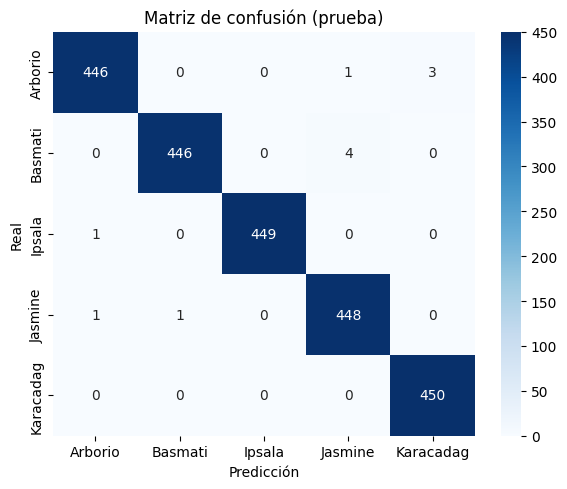

In [ ]:
#1. Pérdida y precisión globales
perdida_prueba, precision_prueba = model.evaluate(test_ds)
print(f"Prueba -> pérdida: {perdida_prueba:.4f} | precisión: {precision_prueba:.4f}")


#2. Predicciones del modelo para cada imagen de prueba

#5 probabilidades por imagen
probabilidades = model.predict(test_ds)

#clase con la probabilidad más alta
y_pred = np.argmax(probabilidades, axis=1)

#clase real de cada imagen
y_true = np.array(y_test)


#3. Reporte con precisión, recall y F1 por variedad
reporte = classification_report(
    y_true,
    y_pred,
    target_names=CLASSES,
    digits=4,
)
print(reporte)


#4. Matriz de confusión
matriz_de_confusion = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    matriz_de_confusion,
    #escribir el número dentro de cada celda
    annot=True,
    #mostrar los números como enteros
    fmt='d',
    #paleta de colores
    cmap='Blues',
    #nombres de las columnas
    xticklabels=CLASSES,
    #nombres de las filas
    yticklabels=CLASSES,
)
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.title('Matriz de confusión (prueba)')

plt.tight_layout()
plt.savefig('matriz_confusion.png', dpi=150)
plt.show()

Mostrar ejemplos de imágenes que el modelo clasificó mal

Errores en prueba: 11 de 2250


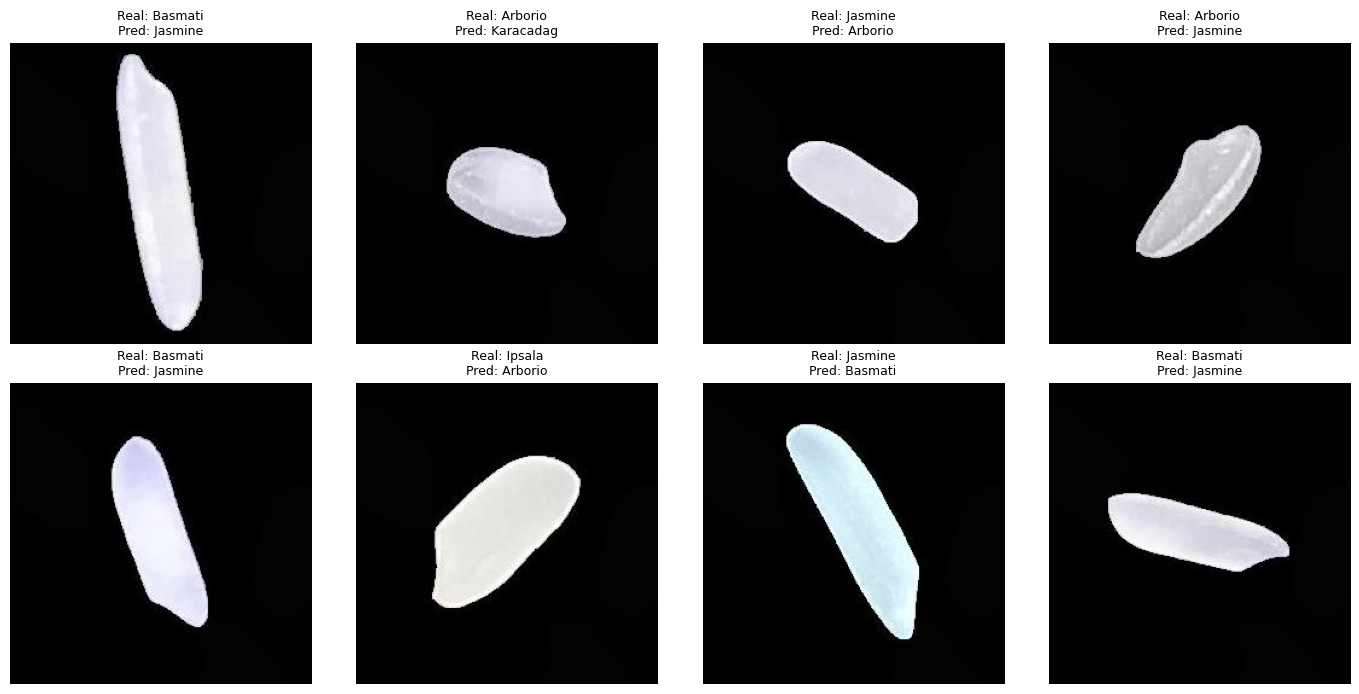

In [ ]:
#posiciones (índices) de las imágenes donde la predicción no coincide con la clase real
indices_errores = np.where(y_pred != y_true)[0]
total_errores = len(indices_errores)

print("Errores en prueba:", total_errores, "de", len(y_true))

#mostrar como máximo 8 errores (la cuadrícula tiene 8 recuadros)
cantidad_a_mostrar = min(8, total_errores)

#solo dibujar si hay al menos un error
if cantidad_a_mostrar > 0:
    figura, ejes = plt.subplots(2, 4, figsize=(14, 7))
    lista_de_ejes = ejes.ravel()   # convierte la cuadrícula 2x4 en una lista simple de 8 recuadros

    #dibujar un error en cada recuadro
    primeros_errores = indices_errores[:cantidad_a_mostrar]
    for eje, indice in zip(lista_de_ejes, primeros_errores):
        imagen = plt.imread(p_test[indice])

        clase_real = CLASSES[y_true[indice]]
        clase_predicha = CLASSES[y_pred[indice]]

        eje.imshow(imagen)
        eje.set_title(f"Real: {clase_real}\nPred: {clase_predicha}", fontsize=9)
        eje.axis('off')

    #si hubo menos de 8 errores, apagar los recuadros que quedaron vacíos
    for eje in lista_de_ejes[cantidad_a_mostrar:]:
        eje.axis('off')

    plt.tight_layout()
    plt.savefig('errores.png', dpi=150)
    plt.show()

Mostrar 10 predicciones al azar del conjunto de prueba (verde = acierto, rojo = error)

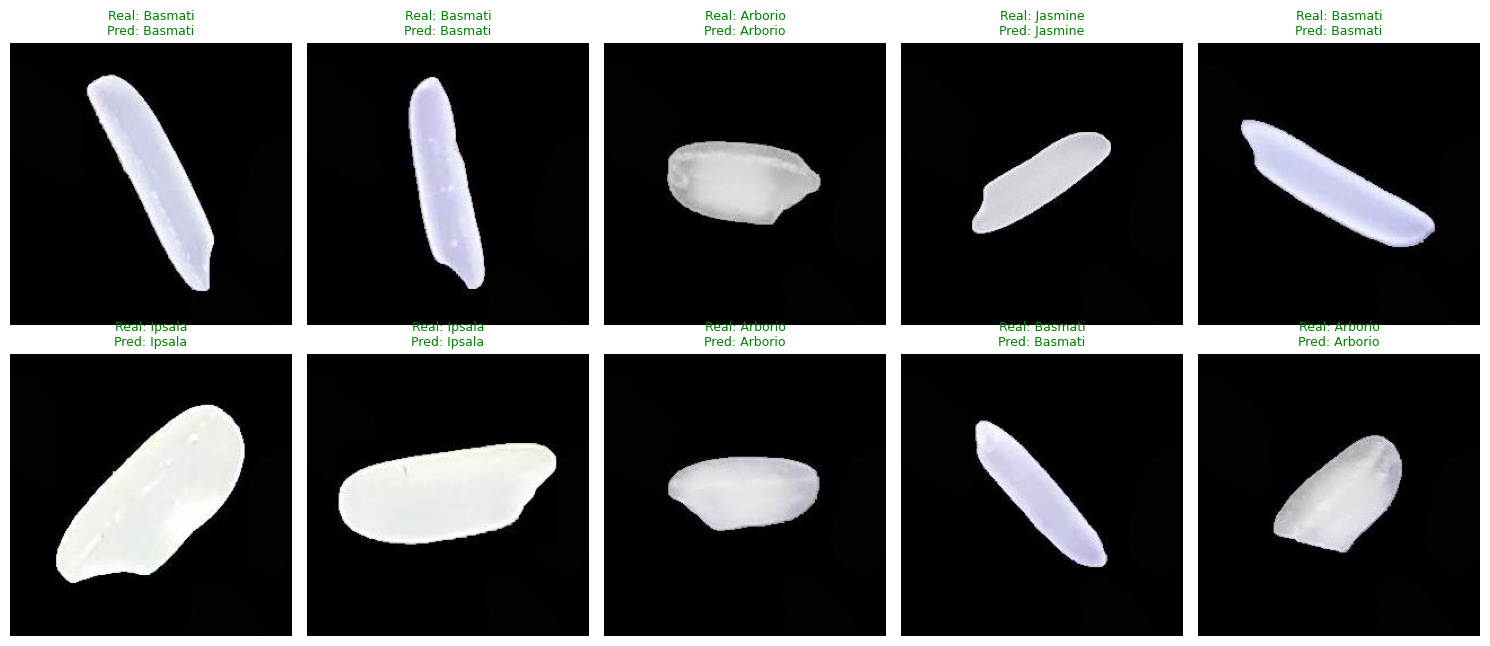

In [ ]:
CANTIDAD_DE_EJEMPLOS = 10

#elegir 10 posiciones al azar entre las 2,250 imágenes de prueba
#siempre las mismas, gracias a la semilla
generador_aleatorio = random.Random(1)
posiciones_disponibles = range(len(p_test))
indices_elegidos = generador_aleatorio.sample(posiciones_disponibles, CANTIDAD_DE_EJEMPLOS)

#cuadrícula de 2 filas x 5 columnas = 10 recuadros
figura, ejes = plt.subplots(2, 5, figsize=(15, 6.5))

#convierte la cuadrícula en una lista simple de 10 recuadros
lista_de_ejes = ejes.ravel()

for eje, indice in zip(lista_de_ejes, indices_elegidos):
    #cargar y dibujar la imagen
    imagen = plt.imread(p_test[indice])
    eje.imshow(imagen)

    #clase real y clase que predijo el modelo, como nombres
    clase_real = CLASSES[y_true[indice]]
    clase_predicha = CLASSES[y_pred[indice]]

    #¿acertó el modelo?
    acierto = (clase_predicha == clase_real)

    #cerde si acertó, rojo si se equivocó
    if acierto:
        color_titulo = 'green'
    else:
        color_titulo = 'red'

    eje.set_title(f"Real: {clase_real}\nPred: {clase_predicha}", fontsize=9, color=color_titulo)
    eje.axis('off')

plt.tight_layout()
plt.savefig('predicciones.png', dpi=150)
plt.show()